# LangChain Agents Bootcamp - Financial Analysis with Gemini

Complete guide to building production-ready agents with memory, middleware, and streaming.

https://docs.langchain.com/oss/python/langchain/middleware/built-in

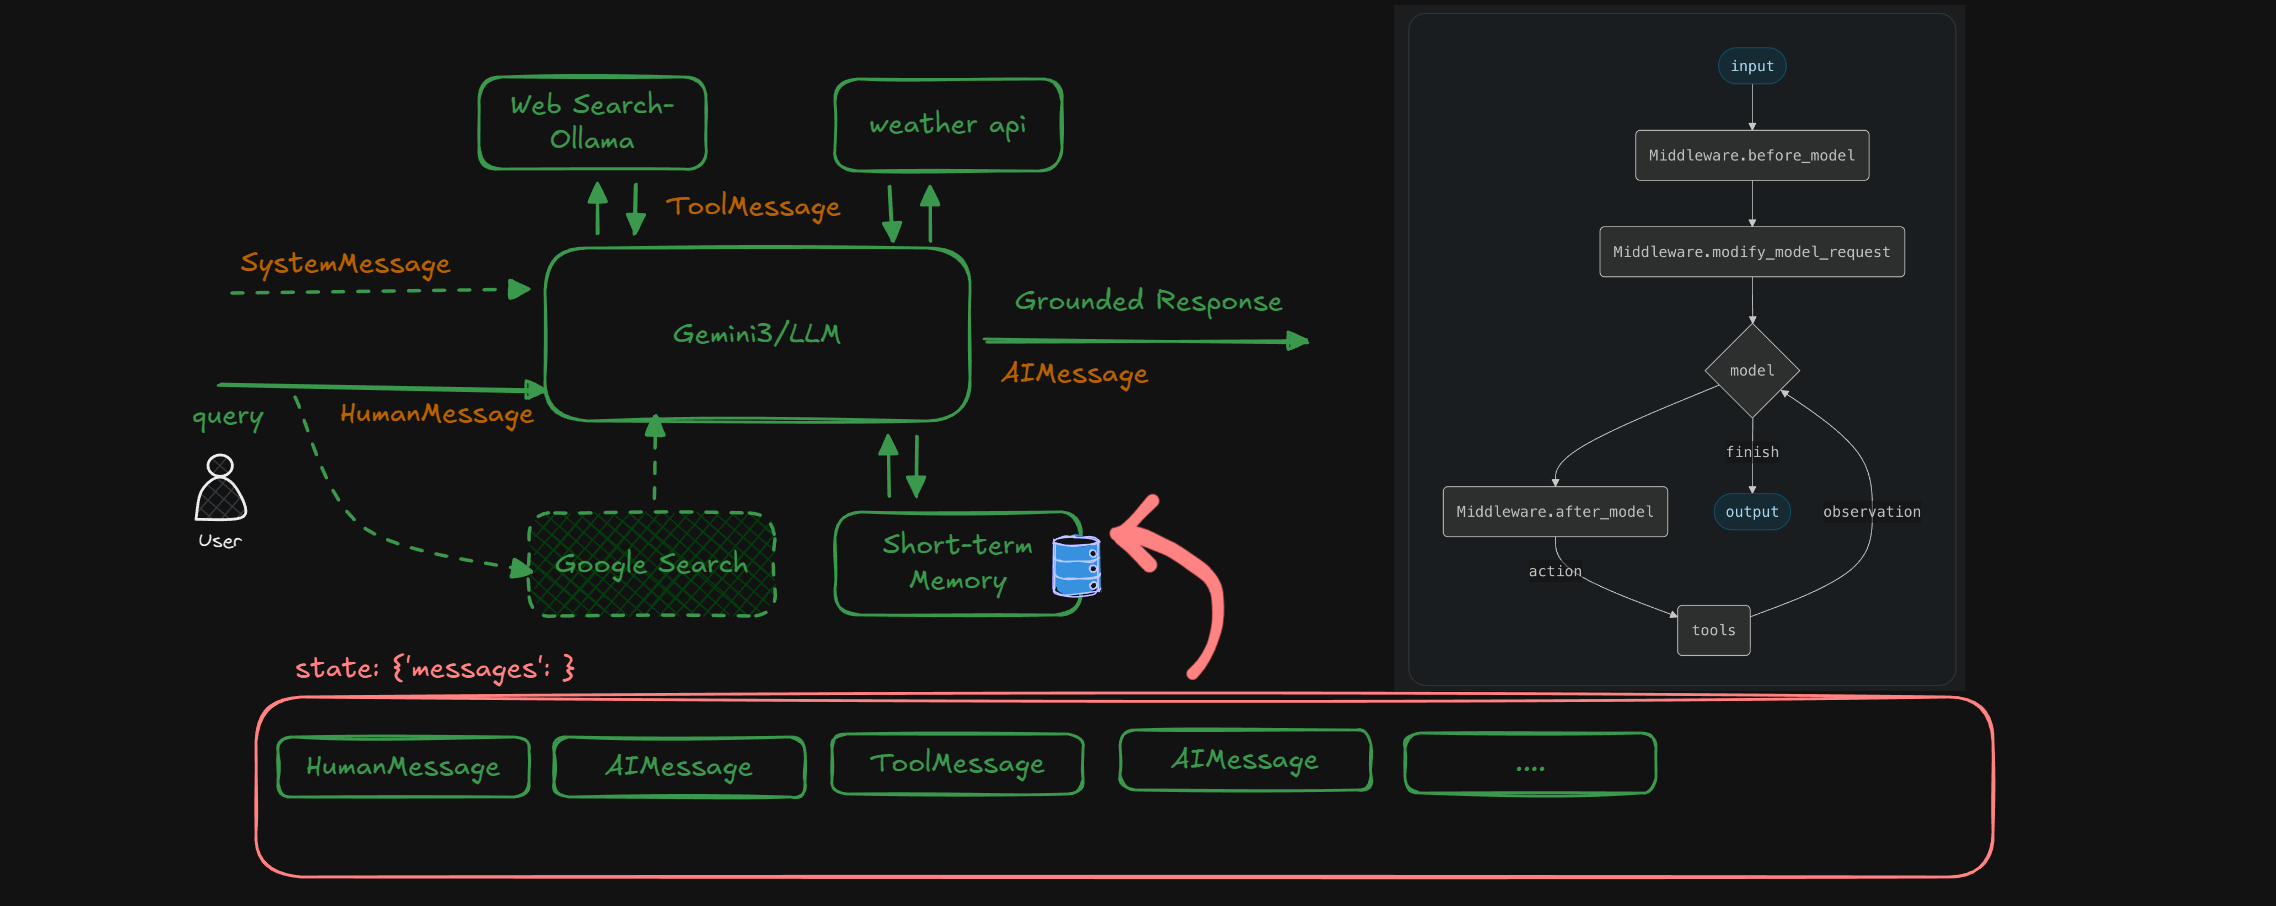

## Overview

This notebook covers:
- **Short-term Memory**: Persist conversation state with SQLite
- **Built-in Middleware**: Production patterns (summarization, limits, PII detection, todo tracking)
- **Structured Output**: Type-safe agent responses with Pydantic
- **Streaming Modes**: Real-time updates (`messages`, `updates`, `values`)

## Setup

Initialize model and tools for financial analysis.

In [1]:
import os
from dotenv import load_dotenv

load_dotenv()

True

In [2]:
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain.agents import create_agent
from langchain.messages import SystemMessage, HumanMessage, AIMessage, ToolMessage
from scripts import base_tools

In [3]:
model = ChatGoogleGenerativeAI(model='gemini-2.5-flash') 

In [4]:
system_prompt = "You are a financial analyst specializing in tech stocks.\nProvide data-driven analysis with clear insights. you have access to web_search tools and get_weather tools."

## 1. Basic Agent

Create a simple agent with tools but no memory.

In [5]:
agent = create_agent(model=model, 
                     tools= [base_tools.web_search, 
                             base_tools.get_weather],
                               system_prompt=system_prompt) 

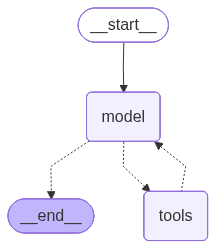

In [6]:
agent

In [9]:
query = "what's apple's current stock price?"
response = agent.invoke({'messages': [HumanMessage(query)]})

In [10]:
response

{'messages': [HumanMessage(content="what's apple's current stock price?", additional_kwargs={}, response_metadata={}, id='c580c701-8c35-48bf-a4d3-b30f8db8ddbb'),
  AIMessage(content='', additional_kwargs={'function_call': {'name': 'web_search', 'arguments': '{"query": "Apple stock price"}'}, '__gemini_function_call_thought_signatures__': {'67eec543-47d8-4bed-a0fb-1a2a394c00c4': 'CtYBAQw51sePRf1Ny7isa3Vs0phfSQLlFFHwdGcZOKNhSDotBdC/pNjUY5OAKiaMY2tP0TBGRBBGHdxr3XgURWKFVgIl+YXTi7fLvFib47dPR1CIJwjuCZLqEWGAQ3M7kvY3U7ljAcuVdIVVsmSy02idC/bNZetRI4OV8R/a/zthp+AVrj/szb+FIr2XXZ4d8CQykte2vsAWiRYLDMBigyXxUsykROtc2alpUVjtIjeAf9gYgPz2A7Ct0aaXhpz1xQ4EXti5zG4xxGW2jE4vMVxbjOoU44Kfhw=='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--019e60b3-a3cb-7b72-b783-aed7ede62d7d-0', tool_calls=[{'name': 'web_search', 'args': {'query': 'Apple stock price'}, 'id': '67eec543-47d8-4bed-a0fb-1a2a394c00c4', 'type': 'too

In [ ]:
query = "what's apple's current stock price? and what is the latest weather in Mumbai?"
response = agent.invoke({'messages': [HumanMessage(query)]})

In [11]:
response

{'messages': [HumanMessage(content="what's apple's current stock price? and what is the latest weather in Mumbai?", additional_kwargs={}, response_metadata={}, id='3021cc07-844c-4b59-9d9e-de94499b5c87'),
  AIMessage(content='', additional_kwargs={'function_call': {'name': 'get_weather', 'arguments': '{"location": "Mumbai"}'}, '__gemini_function_call_thought_signatures__': {'89d3268d-6f1d-4e0f-890f-2f976c14afaa': 'CtgCAQw51sdZGKD3qkWMOaloSE9RI6wmnP1Ys09MU3U8eIUiGEqgUyCFtNlQs7h0ilrQtK/FgVsziBbnLQeO39AIRvJR5SnN7gCKHmxrfT8IJrabFXNoeKK1N+QiUy4MqX6mxKO8XhUkg7R05382lmJIvhGcHqTSB3Q3RQLffgGnhhAGoEFeK7yCrM3Mw/kBweA2c+2gHhjl5oBpBJEbIl0NEew+J8W6rQiTSu2ckSV+/Ozv+O/w6P9fgcuOStTfeiCJ9cZg0vBk2KwiKzXBR1QWDlRh8PSjIciCRJIdc3q9jngWBGltc49v5H9LfOVnCsBCJTOeI1v5ordNiNfvKVrL8fCHo4uA/xCq7II1un1nNEVytnGQ9ZiqTKREAhW6lIUtK55VnAWt1JjnA1e3Yki2ijW6vB/MptxxfdWbSDk+YzpaAyrZaKP/wv2ygVFV6V6vAAI4ORwI8Vo='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash', 'safety_ratings': [], 'model_provide

In [15]:
print(response['messages'][-1].text)

Apple's current stock price is $308.82, as of May 22, 2026, 4:00 p.m. ET, reflecting a change of +$3.83.

In Mumbai, the weather is currently 33.1°C (91.6°F) with mist. It feels like 42°C (107.6°F) due to 63% humidity. There is no chance of rain, and the wind is blowing from the WSW at 11.5 kph (7.2 mph). The UV index is 10. This information was last updated on May 26, 2026, 11:00 AM.


## 2. Short-term Memory with SQLite

Add conversation persistence using SQLite checkpointer. Agent remembers previous turns within a session.

In [7]:
from langgraph.checkpoint.sqlite import SqliteSaver
import sqlite3

conn = sqlite3.connect("data/financial_agent.db", check_same_thread=False)
checkpointer = SqliteSaver(conn=conn)

In [8]:
agent_memory = create_agent(
    model=model,
    tools=[base_tools.web_search, base_tools.get_weather],
    system_prompt=system_prompt,
    checkpointer = checkpointer)

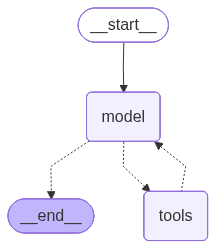

In [16]:
agent_memory

In [17]:
config = {"configurable": {"thread_id": "memory_session"}}
response = agent_memory.invoke({'messages': [query]}, config=config)

In [18]:
response

{'messages': [HumanMessage(content="what's apple's current stock price? and what is the latest weather in Mumbai?", additional_kwargs={}, response_metadata={}, id='4248b11c-34f0-4fbc-bf34-28dcf9739cc9'),
  AIMessage(content='', additional_kwargs={'function_call': {'name': 'get_weather', 'arguments': '{"location": "Mumbai"}'}, '__gemini_function_call_thought_signatures__': {'b523475e-384d-466c-8251-f85f47eec234': 'CugCAQw51sckrfOZ1FvxGwhHGsg2/P8WtVP8mp3Ph05M2N27+0exIpS+l+k9lqXXtYqoskYE7Ve3ABTArB2Jn0yimgnVZPyGEc/5KIcQUMQIh6hfxtA9pTbUM5JHSgFgm045HEOzMwDXLML+p87/i5EdLNmnKEefRZBo0Vvu9BpZA/onNb0plgxtb08BxOM+pA9Sp8rMB9YvDQ0MJXsAC5dhjIibd1GLWJ2+cUoXPZzI0qiIIotZdIXh+qeDScOe/R36s5ErdwdNQtTH/CkxOGiqXfK4ey+RzeazP42+KRqEUF4iIP5vbljz74pkNBaauT9u1MABj+O1t4jBgbGt+1vT7P93lE2RtT1gH1ccjJkd/JayUPYON1aPEh4EXBiYrwQu/wuh1XinDMEIPvCaR6nMSRt7XDxzW8PSDv4NsBLKVyAAp/O5+nmljabJTl0XKZ0/Ymevhvvt0acR56G+D4CHlr660xslteMp'}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash', 'safety_ratings'

In [19]:
response = agent_memory.invoke({'messages': ["what is the latest US stock news"]}, config=config)

In [20]:
response

{'messages': [HumanMessage(content="what's apple's current stock price? and what is the latest weather in Mumbai?", additional_kwargs={}, response_metadata={}, id='4248b11c-34f0-4fbc-bf34-28dcf9739cc9'),
  AIMessage(content='', additional_kwargs={'function_call': {'name': 'get_weather', 'arguments': '{"location": "Mumbai"}'}, '__gemini_function_call_thought_signatures__': {'b523475e-384d-466c-8251-f85f47eec234': 'CugCAQw51sckrfOZ1FvxGwhHGsg2/P8WtVP8mp3Ph05M2N27+0exIpS+l+k9lqXXtYqoskYE7Ve3ABTArB2Jn0yimgnVZPyGEc/5KIcQUMQIh6hfxtA9pTbUM5JHSgFgm045HEOzMwDXLML+p87/i5EdLNmnKEefRZBo0Vvu9BpZA/onNb0plgxtb08BxOM+pA9Sp8rMB9YvDQ0MJXsAC5dhjIibd1GLWJ2+cUoXPZzI0qiIIotZdIXh+qeDScOe/R36s5ErdwdNQtTH/CkxOGiqXfK4ey+RzeazP42+KRqEUF4iIP5vbljz74pkNBaauT9u1MABj+O1t4jBgbGt+1vT7P93lE2RtT1gH1ccjJkd/JayUPYON1aPEh4EXBiYrwQu/wuh1XinDMEIPvCaR6nMSRt7XDxzW8PSDv4NsBLKVyAAp/O5+nmljabJTl0XKZ0/Ymevhvvt0acR56G+D4CHlr660xslteMp'}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash', 'safety_ratings'

In [21]:
for res in response['messages']:
    if isinstance(res, AIMessage):
        print(res.usage_metadata)

{'input_tokens': 255, 'output_tokens': 109, 'total_tokens': 364, 'input_token_details': {'cache_read': 0}, 'output_token_details': {'reasoning': 77}}
{'input_tokens': 4034, 'output_tokens': 401, 'total_tokens': 4435, 'input_token_details': {'cache_read': 0}, 'output_token_details': {'reasoning': 247}}
{'input_tokens': 4197, 'output_tokens': 65, 'total_tokens': 4262, 'input_token_details': {'cache_read': 0}, 'output_token_details': {'reasoning': 47}}
{'input_tokens': 6876, 'output_tokens': 408, 'total_tokens': 7284, 'input_token_details': {'cache_read': 0}}


## Built-in Middleware

## 3. Middleware: Summarization

Automatically summarize old messages when history grows too long.

**Use Case**: Long conversations that exceed context windows.

In [9]:
from langchain.agents.middleware import SummarizationMiddleware

In [10]:
agent_summary = create_agent(
    model=model,
    tools=[base_tools.web_search, base_tools.get_weather],
    system_prompt=system_prompt,
    checkpointer=checkpointer,
    middleware=[
        SummarizationMiddleware(
            model=ChatGoogleGenerativeAI(model='gemini-2.5-flash'),
            trigger=[("messages", 10)],
            keep=("messages", 5)
        )
    ]
)

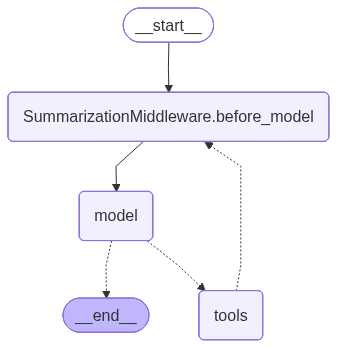

In [24]:
agent_summary

In [25]:
response = agent_summary.invoke({'messages': ['what is the stock price of Microsoft and Apple. What is the latest weather in yaounde. What is the latest news on douala Stock market?. Use the web search tool.']}, config=config)

In [26]:
response['messages'][0].pretty_print()

================================ Human Message =================================

Here is a summary of the conversation to date:

## SESSION INTENT
The user's primary goal is to obtain the current stock prices for Microsoft and Apple, the latest weather information for Yaounde, and the latest news regarding the Douala Stock Market.

## SUMMARY
The user has requested three distinct pieces of information: stock prices for Microsoft (MSFT) and Apple (AAPL), weather in Yaounde, and news on the Douala Stock Market. The user explicitly instructed to use the web search tool to retrieve this information. No actions have been taken yet, and no choices have been made or rejected.

## ARTIFACTS
None.

## NEXT STEPS
1. Use the web search tool to find the current stock price of Microsoft (MSFT).
2. Use the web search tool to find the current stock price of Apple (AAPL).
3. Use the web search tool to find the latest weather information for Yaounde.
4. Use the web search tool to find the latest news 

In [27]:
response['messages'][-1].text

"Here's the information you requested:\n\n**Microsoft (MSFT) Stock Price:**\nAs of May 22, 2026, 4:00:00 PM GMT-4, Microsoft (MSFT) is trading at **$418.57**, down 0.12% (-$0.52) for the day.\n\n**Apple (AAPL) Stock Price:**\nAs of May 22, 2026, 4:00:01 PM GMT-4, Apple (AAPL) is trading at **$308.82**, up 1.26% (+$3.83) for the day.\n\n**Weather in Yaounde:**\nAs of May 26, 2026, 08:15 local time, the weather in Yaounde, Cameroon is **21.6°C (71°F)** with **fog** and **98% humidity**. There is a **100% chance of rain**.\n\n**Douala Stock Market News:**\nRecent news from May 7-8, 2026, highlights the significant debut of **BGFI Holding Corporation** on the Central African Stock Exchange (BVMAC) in Douala. This event **more than tripled BVMAC's equity market capitalization**, increasing it by over 246% from CFA479 billion to CFA1.658 trillion. BGFI Holding is now the largest company on the exchange, holding 38% of the equity market. The IPO included a stock split, making shares more acce

In [28]:
response

{'messages': [HumanMessage(content="Here is a summary of the conversation to date:\n\n## SESSION INTENT\nThe user's primary goal is to obtain the current stock prices for Microsoft and Apple, the latest weather information for Yaounde, and the latest news regarding the Douala Stock Market.\n\n## SUMMARY\nThe user has requested three distinct pieces of information: stock prices for Microsoft (MSFT) and Apple (AAPL), weather in Yaounde, and news on the Douala Stock Market. The user explicitly instructed to use the web search tool to retrieve this information. No actions have been taken yet, and no choices have been made or rejected.\n\n## ARTIFACTS\nNone.\n\n## NEXT STEPS\n1. Use the web search tool to find the current stock price of Microsoft (MSFT).\n2. Use the web search tool to find the current stock price of Apple (AAPL).\n3. Use the web search tool to find the latest weather information for Yaounde.\n4. Use the web search tool to find the latest news on the Douala Stock Market.\n5.

## 4. Middleware: Model and Tool Call Limit

Limit the number of model calls per request to prevent runaway costs.

**Exit Behaviors**: `"end"` (stop) or `"continue"` (proceed without model)

In [11]:
from langchain.agents.middleware import ModelCallLimitMiddleware
from langchain.agents.middleware import ToolCallLimitMiddleware
from langchain.agents.middleware import ModelFallbackMiddleware

In [30]:
agent_limit = create_agent(
    model=model,
    tools=[base_tools.web_search, base_tools.get_weather],
    system_prompt=system_prompt,
    checkpointer=checkpointer,
    middleware=[
        SummarizationMiddleware(
            model=ChatGoogleGenerativeAI(model='gemini-2.5-flash'),
            trigger=[("messages", 15)],
            keep=("messages", 5)
        ),
        ModelCallLimitMiddleware(run_limit=2, exit_behavior="end"),
        ToolCallLimitMiddleware(run_limit=2, exit_behavior='continue'),
        ModelFallbackMiddleware(ChatGoogleGenerativeAI(model='gemini-3.1-flash-lite-preview'))
    ]
)

In [31]:
config = {'configurable': {'thread_id': 'limit_session'}}
response = agent_limit.invoke({'messages': ['what is the total distance between earth and moon. what is the latest news on trump. what is the latest weather of London?']}, config)


In [32]:
response

{'messages': [HumanMessage(content='what is the total distance between earth and moon. what is the latest news on trump. what is the latest weather of London?', additional_kwargs={}, response_metadata={}, id='cdcc4ad8-4861-45a9-b7e1-89bb1c3b0c8a'),
  AIMessage(content='', additional_kwargs={'function_call': {'name': 'get_weather', 'arguments': '{"location": "London"}'}, '__gemini_function_call_thought_signatures__': {'fe1cb8f9-1334-474b-b8a0-9431a7df19eb': 'CsoFAQw51scwRAA2Ytcovxc3ucQnD7KQwixKmuOXyjjdeSxrlNsgi8gzoUlqn8zxd6/ekNURr7hU69aA99K96fquQr0Z0a3OuRBRxny2K1TnFb2Mbuwcy/FpjmvotfBL9bGf83Jnsll42uSais0oR0Iyk9VtSh2FU5ZYjqMKtR2runnoHSY96iwiJ80pQ1IHU+zzVmR1HOttaFsiAcFCnxRR3eLMHv6dGx5WlLc4vqbbaZHMtE3r8OVV3Q2WM4e/4RROInqvJGv5YUVGshXbg6aka1w3LU0cghI+lK4UZmVn+uTz8+vaqMoHabZ4YxEvZrYq0XzPZMdFEx+Vq9CmkTsnLotQ8lc1063UB1LzZooQ+Z8zpFqE6JEPcfbKv13YA+YrHssIeu0HiV+7KSaZ0m8VK7ksdOWcylkJFRZo3z+IpH2GR7Z+1nexa6kbfRnZg3te/ri9MyHqtAZFmENQ/IsboWR+hMINZ6bjo6oTGfSusCsBiCDtzV9ub7IH2Pj7yA06CaiIzwK1IBs4wB0oTzN2ut

In [33]:
response = agent_limit.invoke({'messages': ['tell me 3 facts about the earth']}, config)
response

{'messages': [HumanMessage(content='what is the total distance between earth and moon. what is the latest news on trump. what is the latest weather of London?', additional_kwargs={}, response_metadata={}, id='cdcc4ad8-4861-45a9-b7e1-89bb1c3b0c8a'),
  AIMessage(content='', additional_kwargs={'function_call': {'name': 'get_weather', 'arguments': '{"location": "London"}'}, '__gemini_function_call_thought_signatures__': {'fe1cb8f9-1334-474b-b8a0-9431a7df19eb': 'CsoFAQw51scwRAA2Ytcovxc3ucQnD7KQwixKmuOXyjjdeSxrlNsgi8gzoUlqn8zxd6/ekNURr7hU69aA99K96fquQr0Z0a3OuRBRxny2K1TnFb2Mbuwcy/FpjmvotfBL9bGf83Jnsll42uSais0oR0Iyk9VtSh2FU5ZYjqMKtR2runnoHSY96iwiJ80pQ1IHU+zzVmR1HOttaFsiAcFCnxRR3eLMHv6dGx5WlLc4vqbbaZHMtE3r8OVV3Q2WM4e/4RROInqvJGv5YUVGshXbg6aka1w3LU0cghI+lK4UZmVn+uTz8+vaqMoHabZ4YxEvZrYq0XzPZMdFEx+Vq9CmkTsnLotQ8lc1063UB1LzZooQ+Z8zpFqE6JEPcfbKv13YA+YrHssIeu0HiV+7KSaZ0m8VK7ksdOWcylkJFRZo3z+IpH2GR7Z+1nexa6kbfRnZg3te/ri9MyHqtAZFmENQ/IsboWR+hMINZ6bjo6oTGfSusCsBiCDtzV9ub7IH2Pj7yA06CaiIzwK1IBs4wB0oTzN2ut

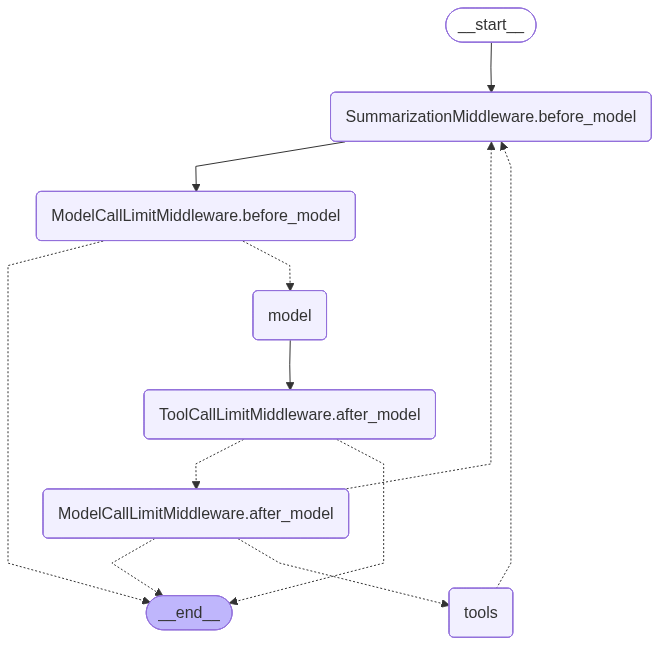

In [34]:
agent_limit

## 5. Middleware: Guardrails and PII Detection

Automatically detect and redact/mask personally identifiable information.

**Strategies**: `"redact"` (remove), `"mask"` (replace with ***), `"block"` (prevent request)

In [35]:
from langchain.agents.middleware import PIIMiddleware


In [36]:
agent_pii = create_agent(
    model=model,
    tools=[base_tools.web_search, base_tools.get_weather],
    system_prompt=system_prompt,
    checkpointer=checkpointer,
    middleware=[
        PIIMiddleware("api_key", detector=r"sk-[a-zA-Z0-9]{32}", strategy="block"),
        PIIMiddleware("email", strategy="redact", apply_to_input=True),
        PIIMiddleware("credit_card", strategy="mask", apply_to_input=True),
        PIIMiddleware("url", strategy="redact", apply_to_input=True)
    ])

In [41]:
config = {'configurable': {'thread_id': 'pii_session'}}

response = agent_pii.invoke({'messages': [HumanMessage('Hi, my name is aldorith. here is my email aldorith@gmail.com')]}, config=config)

In [42]:
response

{'messages': [HumanMessage(content='Hi, my name is laxmi kant. here is my email [REDACTED_EMAIL]', additional_kwargs={}, response_metadata={}, id='51d63cce-6251-4073-9001-2293ec1a8088'),
  AIMessage(content="Hello Laxmi Kant, it's a pleasure to meet you. How can I assist you today with tech stock analysis or any other financial inquiries?", additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--019e637a-f903-7c51-9061-1f16f2071657-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 256, 'output_tokens': 30, 'total_tokens': 286, 'input_token_details': {'cache_read': 0}}),
  HumanMessage(content='Hi, my name is aldorith. here is my email [REDACTED_EMAIL]', additional_kwargs={}, response_metadata={}, id='2349dfac-8300-4d18-a1d8-d04ec3ab3c21'),
  AIMessage(content="Hello Aldorith, it's a pleasure to meet you. How can I assist you today with tech stock anal

In [43]:
response = agent_pii.invoke({'messages': 
                             [HumanMessage('Hi, my name is aldorith. here is my email aldorith@gmail.com. my website is https://aldo.com')]}, config=config)

In [44]:
response

{'messages': [HumanMessage(content='Hi, my name is laxmi kant. here is my email [REDACTED_EMAIL]', additional_kwargs={}, response_metadata={}, id='51d63cce-6251-4073-9001-2293ec1a8088'),
  AIMessage(content="Hello Laxmi Kant, it's a pleasure to meet you. How can I assist you today with tech stock analysis or any other financial inquiries?", additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--019e637a-f903-7c51-9061-1f16f2071657-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 256, 'output_tokens': 30, 'total_tokens': 286, 'input_token_details': {'cache_read': 0}}),
  HumanMessage(content='Hi, my name is aldorith. here is my email [REDACTED_EMAIL]', additional_kwargs={}, response_metadata={}, id='2349dfac-8300-4d18-a1d8-d04ec3ab3c21'),
  AIMessage(content="Hello Aldorith, it's a pleasure to meet you. How can I assist you today with tech stock anal

## 6. Middleware: Todo List

Track and manage multi-step tasks within the agent.

In [12]:
from langchain.agents.middleware import TodoListMiddleware

In [13]:
system_prompt

'You are a financial analyst specializing in tech stocks.\nProvide data-driven analysis with clear insights. you have access to web_search tools and get_weather tools.'

In [14]:
agent_todo = create_agent(
    model=model,
    tools=[base_tools.web_search, base_tools.get_weather],
    system_prompt=system_prompt,
    checkpointer=checkpointer,
    middleware=[TodoListMiddleware()]
)

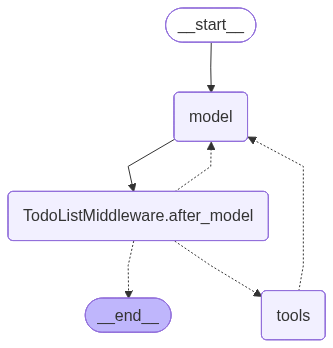

In [15]:
agent_todo

In [16]:
config = {'configurable': {'thread_id': 'todo_session_1'}}

response = agent_todo.invoke(
    {'messages': [HumanMessage("analyze the apple revenue and compare it with competitors")]},
    config=config
)

In [17]:
response

{'messages': [HumanMessage(content='analyze the apple revenue and compare it with competitors', additional_kwargs={}, response_metadata={}, id='86d47069-19e2-4e9e-89dc-aa72d569f8c8'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'finish_reason': 'MALFORMED_FUNCTION_CALL', 'model_name': 'gemini-2.5-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--019e639a-3df8-7873-87c8-fe54e7b2f0e1-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1417, 'output_tokens': 0, 'total_tokens': 1417, 'input_token_details': {'cache_read': 0}}),
  HumanMessage(content='analyze the apple revenue and compare it with competitors', additional_kwargs={}, response_metadata={}, id='c1118b86-1ddd-4129-8902-68ee4c291f62'),
  AIMessage(content='', additional_kwargs={'function_call': {'name': 'write_todos', 'arguments': '{"todos": [{"status": "in_progress", "content": "Identify Apple\'s main competitors."}, {"status": "pending", "content": "Retrieve 

In [18]:
print(response['messages'][-1].text)

I have already completed this analysis in the previous turn. Here is the data-driven analysis of Apple's revenue compared to its key competitors for their respective fiscal year 2025:

As a financial analyst specializing in tech stocks, here's a data-driven analysis of Apple's revenue compared to its key competitors for their respective fiscal year 2025:

**Apple's Main Competitors Identified:**
Based on market analysis, Apple's primary competitors across its various business segments (smartphones, PCs, tablets, wearables, services) include:
*   **Samsung:** A major rival in smartphones, tablets, and wearables.
*   **Microsoft:** Competes in PCs (Surface, Windows OEMs), enterprise software, and cloud services.
*   **Alphabet (Google):** Competes with Android in smartphones, services (search, YouTube, cloud), and wearables.

**Revenue Data (Fiscal Year 2025):**

*   **Apple:** $416.161 billion
*   **Alphabet (Google):** $402.84 billion
*   **Microsoft:** $281.7 billion
*   **Samsung:** 

## 7. Streaming: Messages Mode
Three streaming modes for real-time agent updates:
- **`messages`**: Stream individual messages as they're generated
- **`updates`**: Stream state updates after each step
- **`values`**: Stream complete state values

In [19]:
config = {'configurable': {'thread_id': 'stream_session'}}
for chunk in agent.stream({'messages':['tell me about the apple news']}, stream_mode='messages', config=config):
    print(chunk)
    print("------\n")

(AIMessageChunk(content='', additional_kwargs={'function_call': {'name': 'web_search', 'arguments': '{"query": "Apple Inc. news"}'}, '__gemini_function_call_thought_signatures__': {'f704c245-10cb-47bd-a46a-c3ac0c76fd5d': 'Cl0BDDnWxxSeyOpkJ+SV3opx6/A6/3VIz4aQqpM97zxKVoGK3KPfSOOFbup5zgvbeOgbnta9ETaE9rTyhR26YLieBZ4LS41VuQQUeJ4lyPvhXeOV6M/dKoI3ytVjy1sK0wEBDDnWx9Q6T9ewHkdwSZ3Mwvg0zUcGZHFsWB34hBV0ioYctE11J+1XCNKsQ6rFu3eT3g7VlcSRGbmNuHf7xxv8+1BHx1vlz4/VAbAOxiY50S31KYah8J9O5STzKVW48z2/aTyIcZ8oHeQXwHm6JLqrfYglr2IlcM+3+kFMmIb34JaBGPvY2v4GDnqTZZFFZrrNs3tCnJF76OdyA6ut7mvCXEJY1pw8y5Ir12+8CH3pCWmSFcv2wR0FFPTm1W0jsHcDH7oLEiHF0qL0NkZzZVErGRoD'}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--019e789c-073c-7d21-bc8f-3c95eed789ab', tool_calls=[{'name': 'web_search', 'args': {'query': 'Apple Inc. news'}, 'id': 'f704c245-10cb-47bd-a46a-c3ac0c76fd5d', 'type': 'tool_call'}], invalid_tool_calls=[], usage_meta

In [20]:
config = {'configurable': {'thread_id': 'stream_session_1'}}
for chunk in agent.stream({'messages':['tell me about the apple news']}, stream_mode='updates', config=config):
    print(chunk)
    print("------\n")

{'model': {'messages': [AIMessage(content='', additional_kwargs={'function_call': {'name': 'web_search', 'arguments': '{"query": "Apple Inc. news"}'}, '__gemini_function_call_thought_signatures__': {'6abc5495-b295-4351-811c-b3696966df4e': 'CokDAQw51seSGvrHNyuk1sJ7ltvxHI1LnhgC9Jn97NE31CrFl7Q6UeHRSZM3zqcS1bc3DSsT3tk4BqwBtmaELSkhsuQTLqMeRbfPO94yL14HFmDOTGDL2lWhRNGZ0pu+KVgWnnqfMs0Tye/c4/KXYJpztDuvuqpKgQWULmt2TadfhAUImDyNpc8Flik3KEEsF2GcXhK0HCaHAmrlrCT0FDfBmKqOifU5sBmu7uT1GLWRytughl1mI5AECwpHEejA3p9fQzfFkFZQYd6DJQRA4GHOYDoxn2vXT/ZP39aBDH+sVZbqXuCvv2twKOXLhxlT/WfmEMzJdzL38F8DrNCo5FaBaD4PC5PyiRLzVQQ9R3BSkwQuEjZmtKMGeDNx2RUK3YoEzXdwTRvukwDQbmzKDS/1Hpo3g/LnqtCJ+5ZbESaCKW/xhP8NxecdRMetUYVQrBAq4gxBkYRDZkoXA2tQfBhlXETd/Qyvo5ZnAAguK1uEA0rj4XIIZWkWQg9bt3yI1TtdIiaOIH6gF2RX'}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--019e789f-d972-7ae3-905b-f0da7fb021ae-0', tool_calls=[{'name': 'web_search', 'arg

In [21]:
config = {'configurable': {'thread_id': 'stream_session_2'}}
for chunk in agent.stream({'messages':['tell me about the apple news']}, stream_mode='values', config=config):
    print(chunk)
    print("------\n")

{'messages': [HumanMessage(content='tell me about the apple news', additional_kwargs={}, response_metadata={}, id='0b801447-b816-470e-915f-e8aca06efc94')]}
------

{'messages': [HumanMessage(content='tell me about the apple news', additional_kwargs={}, response_metadata={}, id='0b801447-b816-470e-915f-e8aca06efc94'), AIMessage(content='', additional_kwargs={'function_call': {'name': 'web_search', 'arguments': '{"query": "Apple Inc. news"}'}, '__gemini_function_call_thought_signatures__': {'3db13d37-3732-447a-a7a0-9ba28a3d6c05': 'CpYCAQw51sem3Cr3SDY6ERejkqgNgfax+zmzfePgJIF5yYTTLQFBOcx4GGutGn7RMgbhaxQCdQ/MeNgZCiPj7eRHtmBSjFLBWASLMmTLcZ0JOOAsYVf9vvp4kc51mUhnpxSMH3cGw3qlTcbPfQywLl3zlDJtpyaYw5LLfrba8JNSYYy043y8GDugcTiWRuCI+CXNwLvE7x1gmAvvVyr/Ti5wmm/BViWiN+W3ynZhvJQw9diGGMvXWOzYfzg+0ct22sI5oL3JshMdgL4UO//XT2sqxa24CajBUYGPVoSmtJZwlmxJ4iLmylj2PrrLBEKowXcaHp3nH9+PZfu+IY8OV93mp4FWly33NutAwzROnZfc7gSv2YM91AM='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash', 'safet

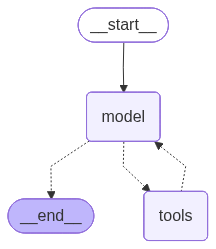

In [106]:
agent

## 8. Structured Output

Return type-safe Pydantic models from agent responses.

In [22]:
from pydantic import BaseModel, Field
from typing import Optional

In [23]:
class FinancialAnalysis(BaseModel):
    company: str = Field (description="Company Name")
    stock_symbol: str = Field (description="Company Stock Symbol")
    current_price: Optional[str] = Field (description="Company's current stock price")
    analysis: str = Field (description="Company's brief analysis")
    recommendation: str = Field (description="What is recommendation? Buy/Hold/Sell")

In [24]:
agent = create_agent(
    model=model,
    tools=[base_tools.web_search, base_tools.get_weather],
    system_prompt=system_prompt,
    response_format = FinancialAnalysis
)

In [25]:
response = agent.invoke({'messages': [HumanMessage('Analyze the apple stock')]})

In [26]:
response

{'messages': [HumanMessage(content='Analyze the apple stock', additional_kwargs={}, response_metadata={}, id='30719df9-fa11-478a-ad54-c13383b27311'),
  AIMessage(content='', additional_kwargs={'function_call': {'name': 'web_search', 'arguments': '{"query": "Apple stock price and recent news"}'}, '__gemini_function_call_thought_signatures__': {'694db29a-4383-4744-8007-5855d2339ff2': 'CrIEAQw51sc8lisRm/h3C3XwANacLSIs0jaSUU4vty2E97Xp5XQ39DK/i4YdfyWyLnpkLC5FDRSBrn3KS1N6uEK5vS5C78UGbFmTdsUkUQIvGYLEeq3tRLI89jO7PzfMB3mJjhA4wHJfGmT7xLRoUhuEBW6qBGQCREgDmpKN21KH9Rk0d7ov0M1QkK5VSp3vckJcJNCOQmnjRj6WWLfeQMyIFAScvZcgrpjXrpwGJ4nwjwjjyO7cCmpmc3wva7cG4l4JpEF1jNOUGZpDexl37kuzxbOtVh8fi6lWmW6vY6XNGTpKQ5fGw7udSHyxMN0SwsOP8rSRyf+UT/rFyvLKh7wZtYctikNRn0leHphiDorFs4+CLcXJXhLBVmYeYeUnbNJpqL5OAURIJma/Meoxn9pIK4vc5kG6XshZdMnXeisyy0m7VmUs6whuYGn+xqlUvrjjUR+7L3E3P5QmYnMeIeG2CP+uUZrTQWGc+TLAQQcPs3Vdx9jwzb9jguahxTnGN/sb6A0qmpRjac/z7uK1AxyWAne4CpNJ7jRtuQaInVrmO1PSF2lq8QkqyQ/SKYjj2HdLdHefOqoXLDHBx+VuY3PmPmT/k46vvfQfWf

In [27]:
response['structured_response'].model_dump()

{'company': 'Apple Inc.',
 'stock_symbol': 'AAPL',
 'current_price': '$312.06',
 'analysis': 'Apple Inc. (AAPL) reported a strong Q2 2026 with quarterly revenue of $111.2 billion, up 17% year-over-year, and diluted EPS of $2.01, up 22% year-over-year. The company achieved record March quarter results for total revenue, iPhone revenue, and EPS, with Services revenue also reaching an all-time high. Key drivers include strong demand for the iPhone 17 lineup and new product introductions like the iPhone 17e, M4-powered iPad Air, and MacBook Neo. Apple also announced new accessibility features powered by Apple Intelligence. The company generated over $28 billion in operating cash flow, increased its cash dividend by 4% to $0.27 per share, and authorized an additional $100 billion for common stock repurchases. A leadership transition is planned for September 1, 2026, with Tim Cook becoming Executive Chairman and John Ternus taking over as CEO.',
 'recommendation': 'Buy'}